# Esperanto topic classification

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Godalberto10/Esperanto-Text-Classification/blob/main/notebooks/classification.ipynb)

Classifies Esperanto paragraphs and web pages into three semantically close
topics: **Christianity** (`kristanismo`), **Islam** (`islamo`) and
**Judaism** (`judismo`).

1. Load the paragraph dataset built from Esperanto Wikipedia.
2. Lemmatize it with [`esperanto_nlp`](https://github.com/Godalberto10/Esperanto-Text-Classification/tree/main/src/esperanto_nlp),
   the rule-based library of this project, and drop stop-words.
3. Train TF-IDF + linear models and pick one with cross-validation.
4. Evaluate on articles the model has never seen and analyse its errors.
5. Classify real Esperanto web pages from outside Wikipedia.

The whole notebook runs on a CPU in under a minute.

## 1. Setup

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    %pip install -q git+https://github.com/Godalberto10/Esperanto-Text-Classification.git

In [2]:
import re
import time
from pathlib import Path

import bs4
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import sklearn
from bs4 import BeautifulSoup
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score,
                             classification_report, f1_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_validate
from sklearn.naive_bayes import ComplementNB
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC

import esperanto_nlp

SEED = 42
CLASSES = ["kristanismo", "islamo", "judismo"]
pd.set_option("display.max_colwidth", 120)

# Versions this run used; requirements.txt pins the ones the results were produced with.
for module in [esperanto_nlp, sklearn, pd, np, matplotlib, requests, bs4]:
    print(f"{module.__name__:15} {module.__version__}")

esperanto_nlp   0.2.0
sklearn         1.9.1
pandas          3.1.0
numpy           2.5.4
matplotlib      3.11.2
requests        2.34.2
bs4             4.15.0


## 2. Data

`dataset.csv` holds one paragraph per row (`text;class`). `sources.csv` lists
the Wikipedia article behind those rows, in the same order, with its
paragraph count and revision id, so every paragraph can be traced back to
the exact version of its article.

The dataset is built by
[`scripts/build_dataset.py`](https://github.com/Godalberto10/Esperanto-Text-Classification/blob/main/scripts/build_dataset.py),
which takes several minutes because requests to Wikipedia are throttled.
By default the notebook loads the published copy. Set `REBUILD_DATASET = True`
to download a fresh one instead; Wikipedia keeps changing, so the numbers
below will differ slightly.

In [3]:
REBUILD_DATASET = False

RAW_URL = "https://raw.githubusercontent.com/Godalberto10/Esperanto-Text-Classification/main"
REPO_DATA = Path("../data") if Path("../data").exists() else f"{RAW_URL}/data"
DATA_DIR = REPO_DATA

if REBUILD_DATASET:
    import subprocess
    import urllib.request

    script = Path("../scripts/build_dataset.py")
    if not script.exists():
        script = Path("build_dataset.py")
        urllib.request.urlretrieve(f"{RAW_URL}/scripts/build_dataset.py", script)
    subprocess.run([sys.executable, str(script), "--output-dir", "data_rebuilt"], check=True)
    DATA_DIR = Path("data_rebuilt")

df = pd.read_csv(f"{DATA_DIR}/dataset.csv", sep=";", encoding="utf-8")
sources = pd.read_csv(f"{DATA_DIR}/sources.csv", sep=";", encoding="utf-8")

df["article"] = np.repeat(sources["title"].to_numpy(), sources["paragraphs"].to_numpy())
assert (df["class"].to_numpy() == np.repeat(sources["class"], sources["paragraphs"]).to_numpy()).all()

print(f"{len(df)} paragraphs from {(sources['paragraphs'] > 0).sum()} articles")
df.sample(5, random_state=SEED)

4566 paragraphs from 596 articles


,text,class,article
1117,"Dudek jarojn post lia morto, oni starigis tombon, nome la Hafezieh, por honori Hafizon en la Ĝardeno Musalla en Ŝira...",islamo,Hafizo
416,"Aliaj modernaj historiistoj, kontraste, estas dividitaj pri la gravo de la batalo, kaj estas ankaŭ konsiderinda malk...",islamo,Batalo de Tours
3587,"Tiuj ĉi instruoj ne estas limigitaj al samseksemo, ĝi estas la ĝenerala premiso por la katolika malpermesado de la a...",kristanismo,Samseksemo kaj katolikismo
2476,"Kaj preninte la manon de la infanino, li diris al ŝi: Talita kumi, tio estas: Knabineto, mi diras al vi: Leviĝu.",kristanismo,Lingvo de Jesuo
881,"la enmeto de la frazero Filioque (""kaj el la Filo"") en la latinlingvan tradukon de la Kredokonfeso nicea-konstantino...",kristanismo,Filiokvo


In [4]:
summary = df.groupby("class").agg(
    paragraphs=("text", "size"),
    articles=("article", "nunique"),
    median_words=("text", lambda s: s.str.split().str.len().median()),
).loc[CLASSES]
summary["share"] = (summary["paragraphs"] / len(df)).round(3)
summary

,paragraphs,articles,median_words,share
class,,,,
kristanismo,2091,200,46.0,0.458
islamo,1085,197,55.0,0.238
judismo,1390,199,47.0,0.304


The classes are reasonably balanced. Paragraphs are not independent, though:
long articles contribute dozens of paragraphs that share names and
vocabulary. The train/test split below keeps every article on one side only.

## 3. Preprocessing with `esperanto_nlp`

Each paragraph becomes a list of lemmas: inflection is stripped
(`preĝejojn` → `preĝejo`), stop-words, punctuation and numbers are dropped,
and everything is lowercased. Because Esperanto is regular, this collapses
the many surface forms of a word into one feature.

In [5]:
nlp = esperanto_nlp.load(normalize_x=True)

doc = nlp("La judoj preĝis en la sinagogoj de Jerusalemo dum la Paska festo.")
pd.DataFrame(
    [(t.text, t.lemma_, t.pos_, str(t.morph), t.is_stop) for t in doc],
    columns=["text", "lemma", "pos", "morph", "is_stop"],
)

,text,lemma,pos,morph,is_stop
0,La,la,DET,,True
1,judoj,judo,NOUN,Case=Nom|Number=Plur,False
2,preĝis,preĝi,VERB,Mood=Ind|Tense=Past|VerbForm=Fin,False
3,en,en,ADP,,True
4,la,la,DET,,True
5,sinagogoj,sinagogo,NOUN,Case=Nom|Number=Plur,False
6,de,de,ADP,,True
7,Jerusalemo,Jerusalemo,PROPN,,False
8,dum,dum,ADP,,True
9,la,la,DET,,True


In [6]:
def lemmas(text):
    """Lowercased content lemmas of a text, without stop-words or numbers."""
    return [
        token.lemma_.lower()
        for token in nlp(text)
        if token.is_alpha and not token.is_stop and len(token) > 1
    ]


def surface_words(text):
    """Baseline without the library: lowercased words as they appear."""
    return re.findall(r"[^\W\d_]+", text.lower())


start = time.perf_counter()
df["lemmas"] = [" ".join(lemmas(text)) for text in df["text"]]
df["words"] = [" ".join(surface_words(text)) for text in df["text"]]
print(f"Processed {len(df)} paragraphs in {time.perf_counter() - start:.1f} s")

n_words = df["words"].str.split().explode().nunique()
n_lemmas = df["lemmas"].str.split().explode().nunique()
print(f"Vocabulary: {n_words} word forms -> {n_lemmas} lemmas without stop-words")
df[["text", "lemmas"]].head(3)

Processed 4566 paragraphs in 2.5 s
Vocabulary: 36666 word forms -> 27664 lemmas without stop-words


,text,lemmas
0,"La abajo estas tradicia virina vesto, kiu estas portata super la aliaj vestaĵoj en kelkaj mezorientaj, islamaj lando...",abajo tradicia virina vesto portata alia vestaĵo kelka mezorienta islama lando areo ĉefe sauda arabio lando persa go...
1,La Abasida Kaliflando (arabe الخلافة العباسية kaj transliterumita al-Ĥilāfah al-‘Abbāsījah) estis la kaliflando estr...,abasida kaliflando arabe الخلافة العباسية transliterumita al-ĥilāfah abbāsījah kaliflando estrita dua dinastio sunai...
2,"La Abasida Kaliflando unue centris sian registaron en Kufa, sed en 762 la kalifo Al-Mansur fondis la urbon Bagdado, ...",abasida kaliflando unue centri registaro kufa kalifo al-mansur fondi urbo bagdado norde sasanida ĉefurbo ktesifono e...


## 4. Train/test split by article

`StratifiedGroupKFold` holds out about 20% of the paragraphs while keeping
each article entirely in train or in test, and the class proportions close
to the full dataset. A random paragraph split would put paragraphs of the
same article on both sides and inflate the scores.

In [7]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
train_idx, test_idx = next(splitter.split(df, df["class"], groups=df["article"]))
train, test = df.iloc[train_idx], df.iloc[test_idx]

assert not set(train["article"]) & set(test["article"])
pd.DataFrame({
    "train": train["class"].value_counts(),
    "test": test["class"].value_counts(),
}).loc[CLASSES]

,train,test
class,,
kristanismo,1673,418
islamo,868,217
judismo,1112,278


## 5. Model selection

TF-IDF over unigrams and bigrams feeds three classic linear models. They are
compared with 5-fold cross-validation on the training set, again grouped by
article, using macro F1 so that every class weighs the same. Each model is
trained once on lemmas and once on raw words to measure what the NLP library
adds.

Article lengths vary a lot: a single long article can contribute 50
paragraphs and teach the model its names (a biography, a battle) as if they
were topic vocabulary. Each paragraph is therefore weighted by
`1 / paragraphs in its article`, so every article counts the same in
training.

In [8]:
def tfidf():
    return TfidfVectorizer(token_pattern=r"\S+", ngram_range=(1, 2),
                           min_df=2, sublinear_tf=True)


def article_weights(frame):
    """Sample weights that make every article weigh the same in training."""
    weights = 1 / frame.groupby("article")["article"].transform("size")
    return (weights / weights.mean()).to_numpy()


models = {
    "Logistic regression": LogisticRegression(C=3, max_iter=2000, class_weight="balanced"),
    "Linear SVM": LinearSVC(C=0.3, class_weight="balanced"),
    "Complement NB": ComplementNB(alpha=0.3),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
results = []
for features in ["lemmas", "words"]:
    for name, classifier in models.items():
        scores = cross_validate(
            Pipeline([("tfidf", tfidf()), ("clf", classifier)]),
            train[features], train["class"], groups=train["article"], cv=cv,
            scoring=["accuracy", "f1_macro"],
            params={"clf__sample_weight": article_weights(train)},
        )
        results.append({
            "model": name, "features": features,
            "accuracy": scores["test_accuracy"].mean(),
            "macro F1": scores["test_f1_macro"].mean(),
            "F1 std": scores["test_f1_macro"].std(),
        })

pd.DataFrame(results).sort_values("macro F1", ascending=False).round(3)

,model,features,accuracy,macro F1,F1 std
0,Logistic regression,lemmas,0.804,0.798,0.031
1,Linear SVM,lemmas,0.803,0.797,0.033
2,Complement NB,lemmas,0.800,0.793,0.038
3,Logistic regression,words,0.790,0.784,0.028
5,Complement NB,words,0.789,0.782,0.033
4,Linear SVM,words,0.788,0.782,0.026


- **Lemmas beat raw words for every model** (about +0.015 macro F1): the
  library merges inflected forms, which matters with only a few thousand
  paragraphs. Weighting by article also adds about +0.01 over unweighted
  training (not shown).
- **The three models are within one standard deviation** of each other.
  Logistic regression is kept because, unlike the SVM, it returns class
  probabilities, which the web page classifier reports.

It is retrained on the whole training set.

In [9]:
model = Pipeline([("tfidf", tfidf()), ("clf", models["Logistic regression"])])
model.fit(train["lemmas"], train["class"], clf__sample_weight=article_weights(train))

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](3,)","['islamo','judismo','kristanismo']"
,"token_pattern token_pattern: str, default=r""(?u)\\b\\w\\w+\\b""Regular expression denoting what constitutes a ""token"", only usedif ``analyzer == 'word'``. The default regexp selects tokens of 2or more alphanumeric characters (punctuation is completely ignoredand always treated as a token separator).If there is a capturing group in token_pattern then thecaptured group content, not the entire match, becomes the token.At most one capturing group is permitted.",'\\S+'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"min_df min_df: float or int, default=1When building the vocabulary ignore terms that have a documentfrequency strictly lower than the given threshold. This value is alsocalled cut-off in the literature.If float in range of [0.0, 1.0], the parameter represents a proportionof documents, integer absolute counts.This parameter is ignored if vocabulary is not None.",2
,"sublinear_tf sublinear_tf: bool, default=FalseApply sublinear tf scaling, i.e. replace tf with 1 + log(tf).",True
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'


## 6. Evaluation on unseen articles

In [10]:
pred = model.predict(test["lemmas"])
print(f"Accuracy: {accuracy_score(test['class'], pred):.3f}")
print(f"Macro F1: {f1_score(test['class'], pred, average='macro'):.3f}\n")
print(classification_report(test["class"], pred, labels=CLASSES, digits=3))

Accuracy: 0.836
Macro F1: 0.833

              precision    recall  f1-score   support

 kristanismo      0.843     0.861     0.852       418
      islamo      0.866     0.806     0.835       217
     judismo      0.803     0.820     0.811       278

    accuracy                          0.836       913
   macro avg      0.837     0.829     0.833       913
weighted avg      0.836     0.836     0.836       913



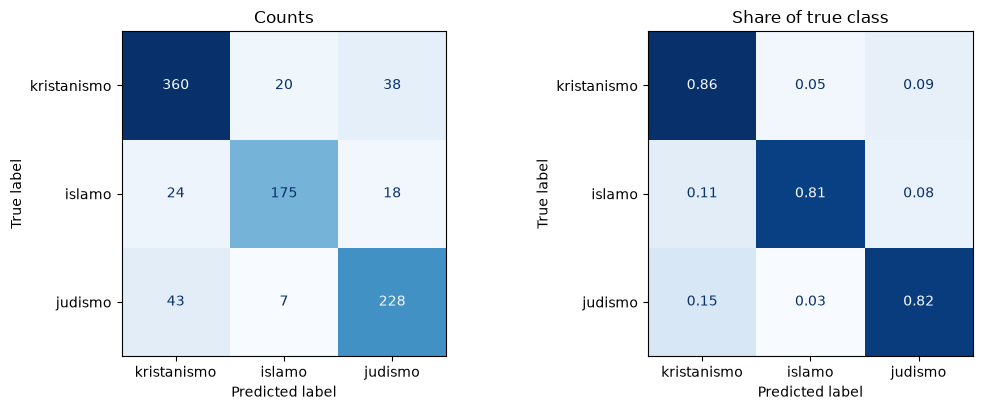

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, normalize, title in [(axes[0], None, "Counts"), (axes[1], "true", "Share of true class")]:
    ConfusionMatrixDisplay.from_predictions(
        test["class"], pred, labels=CLASSES, normalize=normalize,
        values_format=None if normalize is None else ".2f",
        cmap="Blues", colorbar=False, ax=ax,
    )
    ax.set_title(title)
plt.tight_layout()
plt.show()

### What the model learned

The heaviest TF-IDF features of each class are the expected distinctive
vocabulary: places of worship, scriptures, clergy and key figures. A few
remain dataset artifacts: Esperanto Wikipedia covers Jewish life in Poland
and Jewish esperantists in depth, hence *pola* and *esperanto* under
Judaism.

In [12]:
vectorizer, classifier = model.named_steps.values()
vocabulary = vectorizer.get_feature_names_out()
top = {
    label: vocabulary[np.argsort(classifier.coef_[i])[::-1][:15]]
    for i, label in enumerate(classifier.classes_)
}
pd.DataFrame(top)[CLASSES]

,kristanismo,islamo,judismo
0,eklezio,islama,juda
1,kristana,islamo,judo
2,sankta,araba,hebrea
3,jesuo,korano,judismo
4,episkopo,arabe,hebree
5,greka,islamano,israelo
6,kristo,kalifo,jerusalemo
7,kristanismo,moskeo,rabeno
8,papo,ibn,pola
9,johano,muhammad,torao


### Error analysis

Labels are inherited from the article, so some paragraphs are labelled
with a religion they never mention. The table shows the test errors the
model was most confident about.

In [13]:
proba = model.predict_proba(test["lemmas"])
errors = test.assign(
    predicted=pred,
    confidence=proba.max(axis=1),
)[lambda d: d["class"] != d["predicted"]]

print(f"{len(errors)} errors out of {len(test)} test paragraphs")
errors.sort_values("confidence", ascending=False)[
    ["article", "class", "predicted", "confidence", "text"]
].head(8).round(2)

150 errors out of 913 test paragraphs


,article,class,predicted,confidence,text
3753,Sinedrio,judismo,kristanismo,0.98,"La apostoloj Sankta Petro kaj Sankta Johano, Jakobo la Justulo Sankta Stefano la unua martiro, kaj aliaj disĉiploj d..."
1961,Kajafas,judismo,kristanismo,0.91,"En la Nova testamento, Kajafas estas la ĉefpastro, al kiu Jesuo estas kondukita post sia aresto (Mateo 26:57)."
3738,Sinedrio,judismo,kristanismo,0.85,"La evangelioj ofte mencias la Sinedrion, ĝenerale malfavore. Laŭ la evangelioj, la Sinedrio konspiris por mortigi Je..."
3752,Sinedrio,judismo,kristanismo,0.84,Nombraj referencoj al Sinedrio troviĝas en la Nova Testamento. Okazis ke antaŭ la Sinedrio – vidu Aŭgusteno kaj Joze...
607,Elio Toaff,judismo,kristanismo,0.82,La 13-an de aprilo 1986 salutis la papon kaj preĝis kune kun Johano Paŭlo la 2-a dum lia vizito en Granda sinagogo d...
1962,Kajafas,judismo,kristanismo,0.79,"La Londona Biblio kaj PIV2002 havas la grekan formon Kajafas, sed la nomo estas aramea, kaj ne ĉiuj lingvoj kopias l..."
336,Aserta teologio,kristanismo,islamo,0.79,Oni povas pridiskuti kiom da katafatismo kaj apofatismo en la islama religio kaj en la teologioj de Islamismo Budhis...
989,Forpelo de la moriskoj,islamo,judismo,0.78,La forpelo de la moriskoj de Hispanio estis ordonita de la reĝo Filipo la 3-a kaj plenumita laŭgrade inter 1609 kaj ...


In [14]:
correct = test["class"] == pred
bins = pd.cut(proba.max(axis=1), [0, 0.5, 0.7, 0.9, 1.0])
pd.DataFrame({"paragraphs": correct.groupby(bins, observed=True).size(),
              "accuracy": correct.groupby(bins, observed=True).mean().round(3)})

,paragraphs,accuracy
"(0.0, 0.5]",183,0.508
"(0.5, 0.7]",251,0.829
"(0.7, 0.9]",287,0.948
"(0.9, 1.0]",192,0.990


Typical errors fall into three groups:

- **Label noise.** The paragraph is generic (dates, geography, biography)
  and only its article tells the religion. No text classifier can recover
  that label from the paragraph alone.
- **Shared history.** The most confident errors are Jewish institutions and
  figures (the Sanhedrin, the high priest Caiaphas) described through the
  Gospels, or meetings between a rabbi and a pope. The paragraph really is
  about both religions.
- **Short paragraphs** with few distinctive lemmas.

Accuracy rises sharply with the model's confidence, so the probabilities are
informative: low-confidence predictions are where the noise concentrates.

### Measuring label noise

To put a number on the noise, a random sample of 100 test paragraphs
(seed 42) was annotated in
[`data/noise_sample.csv`](https://github.com/Godalberto10/Esperanto-Text-Classification/blob/main/data/noise_sample.csv).
A paragraph is **on topic** (`on_topic = 1`) if a reader who does not know
its article can tell from the paragraph alone that it is about its labelled
religion. It is off topic if it is generic (dates, geography, careers,
bibliography, quotes in another language) or equally about another religion.

In [15]:
annotations = pd.read_csv(f"{REPO_DATA}/noise_sample.csv", sep=";", encoding="utf-8")
noise = test.assign(predicted=pred).sample(100, random_state=SEED)
noise = noise.merge(annotations[["text", "on_topic"]], on="text", how="left")

if noise["on_topic"].isna().any():
    # Only happens with REBUILD_DATASET = True: the annotated paragraphs changed.
    print("The annotated sample does not match this dataset; skipping.")
else:
    noise["correct"] = noise["class"] == noise["predicted"]
    print(f"Off-topic paragraphs: {1 - noise['on_topic'].mean():.0%} of the sample\n")
    display(noise.groupby("class")["on_topic"]
            .agg(paragraphs="size", off_topic=lambda s: 1 - s.mean())
            .loc[CLASSES].round(2))
    display(noise.groupby("on_topic")["correct"]
            .agg(paragraphs="size", accuracy="mean")
            .rename(index={0: "off topic", 1: "on topic"}).round(3))

Off-topic paragraphs: 36% of the sample



,paragraphs,off_topic
class,,
kristanismo,45,0.24
islamo,17,0.29
judismo,38,0.53


,paragraphs,accuracy
on_topic,,
off topic,36,0.611
on topic,64,0.984


- **About a third of the paragraphs are off topic.** Judaism is the
  noisiest class: its category includes many biographies of people of
  Jewish origin (economists, writers, politicians) whose paragraphs never
  mention religion.
- **On-topic paragraphs are classified almost perfectly** (98% accuracy),
  while off-topic ones fall to about 60%, which is still above chance
  because names and places often hint at the article.
- So most of the test errors are not model mistakes but paragraphs whose
  label cannot be inferred from their text. The 0.84 accuracy is a lower
  bound on how well the model recognises the topics themselves.

With 100 paragraphs these figures are estimates (roughly ±10 points), but
the gap between the two groups is far larger than that.

## 7. Classifying web pages

Real Esperanto pages from outside Wikipedia: Bible chapters from
Wikisource (Zamenhof's translation) and news from Wikinews. The page text
is extracted with BeautifulSoup and classified as a whole document. The
`expected` column is a human judgement of the main topic.

In [16]:
HEADERS = {"User-Agent": "esperanto-text-classification/0.2 "
                         "(https://github.com/Godalberto10/Esperanto-Text-Classification)"}
MIN_WORDS = 15


def page_text(url):
    """Downloads a page and returns its main text, one paragraph per line."""
    response = requests.get(url, headers=HEADERS, timeout=20)
    response.raise_for_status()
    soup = BeautifulSoup(response.content, "html.parser")
    root = soup.select_one("#mw-content-text, main, article") or soup.body
    for tag in root.select("script, style, nav, header, footer, table, sup.reference"):
        tag.decompose()
    lines = (" ".join(line.split()) for line in root.get_text("\n").split("\n"))
    return "\n".join(line for line in lines if len(line.split()) >= MIN_WORDS)


def classify_text(text):
    """Probability of each class for a raw Esperanto text."""
    proba = model.predict_proba([" ".join(lemmas(text))])[0]
    return pd.Series(proba, index=model.classes_)[CLASSES]

In [17]:
PAGES = [
    ("https://eo.wikisource.org/wiki/Nova_Testamento/Al_la_Romanoj/1", "kristanismo"),
    ("https://eo.wikinews.org/wiki/Forpasis_la_papo_Francisko", "kristanismo"),
    ("https://eo.wikinews.org/wiki/Imamo_mortis_en_atako_al_ŝijaista_moskeo_en_Belgio", "islamo"),
    ("https://eo.wikinews.org/wiki/Turkio_transformis_Hagia_Sofia_je_moskeo", "islamo"),
    ("https://eo.wikinews.org/wiki/Parto_de_la_placo_de_la_Muro_de_lamentadoj_disfalis_pro_fosadoj", "judismo"),
    ("https://eo.wikisource.org/wiki/Malnova_Testamento_(Zamenhof)/Readmono/34", "judismo"),
    ("https://eo.wikisource.org/wiki/La_golemo", "judismo"),
]

rows = []
for url, expected in PAGES:
    try:
        text = page_text(url)
    except requests.RequestException as error:
        print(f"Skipped {url}: {error}")
        continue
    proba = classify_text(text)
    rows.append({
        "page": requests.utils.unquote(url.split("/wiki/")[-1]).replace("_", " "),
        "words": len(text.split()),
        **proba.round(3),
        "predicted": proba.idxmax(),
        "expected": expected,
    })

web = pd.DataFrame(rows)
print(f"Correct: {(web['predicted'] == web['expected']).sum()} / {len(web)}")
web

Correct: 6 / 7


,page,words,kristanismo,islamo,judismo,predicted,expected
0,Nova Testamento/Al la Romanoj/1,536,0.911,0.054,0.035,kristanismo,kristanismo
1,Forpasis la papo Francisko,145,0.796,0.139,0.065,kristanismo,kristanismo
2,Imamo mortis en atako al ŝijaista moskeo en Belgio,141,0.272,0.547,0.181,islamo,islamo
3,Turkio transformis Hagia Sofia je moskeo,627,0.230,0.607,0.164,islamo,islamo
4,Parto de la placo de la Muro de lamentadoj disfalis pro fosadoj,58,0.028,0.054,0.918,judismo,judismo
5,Malnova Testamento (Zamenhof)/Readmono/34,268,0.104,0.239,0.657,judismo,judismo
6,La golemo,661,0.494,0.112,0.394,kristanismo,judismo


Six of the seven pages are classified correctly, including two hard cases:
*Hagia Sofia* is about a Christian basilica turned into a mosque, and
*Deuteronomy* is scripture shared by Judaism and Christianity.

The miss, *La golemo*, is a 1928 essay by Lidja Zamenhof that retells the
Jewish legend of the Golem as a moral parable. It mentions a rabbi once and
otherwise uses general religious vocabulary (*Dio*, *sankta*), so the model
hesitates between Christianity and Judaism. It is a fair limit of a
bag-of-words model: the topic is carried by the story, not by the words.

### Try your own text

In [18]:
classify_text(
    "Dum la monato Ramadano la islamanoj fastas de la sunleviĝo ĝis la "
    "sunsubiro kaj vizitas la moskeon por preĝi."
).round(3)

kristanismo    0.023
islamo         0.952
judismo        0.025
dtype: float64

## Conclusions

- A rule-based lemmatizer plus TF-IDF and a linear model is enough to tell
  three closely related religions apart in a language with almost no NLP
  tooling.
- Evaluating on held-out **articles** rather than paragraphs gives an honest
  estimate of performance on new text.
- The main limit is label noise: about a third of the paragraphs inherit a
  label they do not talk about. On paragraphs that are really about their
  religion the model is right 98% of the time. Filtering paragraphs without
  any religious vocabulary when building the dataset would be the next step
  to reduce that noise.

Source code, dataset pipeline and NLP library: [https://github.com/Godalberto10/Esperanto-Text-Classification](https://github.com/Godalberto10/Esperanto-Text-Classification).